In [ ]:
# ==============================================================================
# CELL 1: Setup (imports, settings, seed, device)
# ==============================================================================
import os, glob, random, subprocess, sys
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image
from tqdm import tqdm

# Install missing packages (timm for Swin/MobileNetV3, ultralytics for YOLOv8)
for pkg in ["timm", "ultralytics"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import timm
import ultralytics

# ----------------------------- SETTINGS --------------------------------------
SEED = 42
SPLIT_MODE = "random"      # "random" = paper protocol | "grouped" = no lesion leakage
IMG_SIZE = 224             # classifier input size
CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# Ratio-thresholding augmentation factors (base paper, Table 5)
AUG_FACTOR = {'akiec': 10, 'bcc': 6, 'bkl': 3, 'df': 17, 'mel': 3, 'nv': 1, 'vasc': 14}

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()

# ----------------------------- DEVICE ----------------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device      :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only")
print("GPU count   :", torch.cuda.device_count())
print("torch       :", torch.__version__)
print("timm        :", timm.__version__)
print("ultralytics :", ultralytics.__version__)
print("opencv      :", cv2.__version__)
print("\nCell 1 executed successfully!")

In [ ]:
# ==============================================================================
# CELL 2: Load metadata and locate images
# ==============================================================================
meta_paths = glob.glob('/kaggle/input/**/HAM10000_metadata*', recursive=True)
print("Metadata files found:", meta_paths)
assert meta_paths, "Metadata CSV not found. Add the HAM10000 dataset to this notebook."

meta = pd.read_csv(meta_paths[0])
print("Metadata shape:", meta.shape)
print("Columns:", list(meta.columns))

img_paths = glob.glob('/kaggle/input/**/ISIC_*.jpg', recursive=True)
path_map = {os.path.splitext(os.path.basename(p))[0]: p for p in img_paths}
print("Images found:", len(path_map))

df = meta.copy()
df['image_path'] = df['image_id'].map(path_map)
missing = df['image_path'].isna().sum()
print("Metadata rows without an image:", missing)

df = df.dropna(subset=['image_path']).reset_index(drop=True)
df['label'] = df['dx'].map(CLASS_TO_IDX)

print("\nUsable samples:", len(df))
print("\nClass counts:\n", df['dx'].value_counts())
print("\nUnique lesions:", df['lesion_id'].nunique(), "of", len(df), "images")
print("\nSample rows:")
print(df[['image_id', 'lesion_id', 'dx', 'image_path']].head(3).to_string())

In [ ]:
# ==============================================================================
# CELL 3: Verify images and check sizes
# ==============================================================================
bad = []
sizes = {}

for i, p in enumerate(tqdm(df['image_path'], desc="Verifying images")):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:      # re-open: verify() invalidates the handle
            sizes[im.size] = sizes.get(im.size, 0) + 1
    except Exception as e:
        bad.append(i)

print("\nCorrupt/unreadable images:", len(bad))
if bad:
    df = df.drop(index=bad).reset_index(drop=True)

print("Image size distribution (W x H):", sizes)
print("Usable samples after check:", len(df))
print("\nCell 3 executed successfully!")

In [ ]:
# ==============================================================================
# CELL 4: Train/val split
# ==============================================================================
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

if SPLIT_MODE == "random":
    train_df, val_df = train_test_split(
        df, test_size=0.20, stratify=df['dx'], random_state=SEED)
else:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_idx, va_idx = next(sgkf.split(df, df['dx'], groups=df['lesion_id']))
    train_df, val_df = df.iloc[tr_idx], df.iloc[va_idx]

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("SPLIT_MODE:", SPLIT_MODE)
print("Train / Val:", len(train_df), "/", len(val_df))

dist = pd.concat([train_df['dx'].value_counts().rename('train'),
                  val_df['dx'].value_counts().rename('val')], axis=1)
print("\nClass distribution:\n", dist)

leak = val_df['lesion_id'].isin(set(train_df['lesion_id'])).mean() * 100
print(f"\nVal images sharing a lesion_id with train: {leak:.1f}%")

# Save the split so you can reload it if the Kaggle session restarts
os.makedirs('/kaggle/working', exist_ok=True)
train_df.to_csv('/kaggle/working/train_df.csv', index=False)
val_df.to_csv('/kaggle/working/val_df.csv', index=False)
print("Saved train_df.csv and val_df.csv to /kaggle/working")

In [ ]:
# ==============================================================================
# CELL 5: Intensity normalization stats (mean/std on a train subset)
# ==============================================================================
sample = train_df.sample(n=min(500, len(train_df)), random_state=SEED)

pix = []
for p in tqdm(sample['image_path'], desc="Computing mean/std"):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
    pix.append(im.reshape(-1, 3))

pix = np.concatenate(pix)
DATA_MEAN = pix.mean(axis=0).tolist()
DATA_STD = pix.std(axis=0).tolist()
del pix

print("Dataset mean (RGB):", [round(x, 4) for x in DATA_MEAN])
print("Dataset std  (RGB):", [round(x, 4) for x in DATA_STD])

# ImageNet stats for reference (pretrained Swin/MobileNetV3 expect these)
IMNET_MEAN = [0.485, 0.456, 0.406]
IMNET_STD = [0.229, 0.224, 0.225]
print("ImageNet mean     :", IMNET_MEAN)
print("ImageNet std      :", IMNET_STD)

In [ ]:
# ==============================================================================
# CELL 6 (FIXED): NV = 0 extra copies (majority class is not augmented)
# ==============================================================================
AUG_FACTOR['nv'] = 0

counts = train_df['dx'].value_counts()

plan = pd.DataFrame({
    'train_count': counts,
    'extra_copies': [AUG_FACTOR[c] for c in counts.index],
})
plan['target_count'] = plan['train_count'] * (plan['extra_copies'] + 1)
plan['ratio_to_NV'] = (plan['target_count'] / plan.loc['nv', 'target_count']).round(2)
print("Class-wise augmentation plan:\n", plan)
print("\nTotal after augmentation:", int(plan['target_count'].sum()))

CLASS_COUNTS = np.array([counts.get(c, 0) for c in CLASSES], dtype=np.float32)
CLASS_WEIGHTS = (CLASS_COUNTS.sum() / (len(CLASSES) * CLASS_COUNTS)).tolist()
print("\nClass weights:")
for c, w in zip(CLASSES, CLASS_WEIGHTS):
    print(f"  {c:6s} {w:.3f}")


In [ ]:
# ==============================================================================
# CELL 7: Build YOLO dataset from masks + train YOLOv8n lesion detector
# ==============================================================================
from ultralytics import YOLO

YOLO_DIR = "/kaggle/working/yolo_dataset"
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
    os.makedirs(f"{YOLO_DIR}/{sub}", exist_ok=True)

# ---- locate segmentation masks automatically ----
mask_paths = glob.glob('/kaggle/input/**/*_segmentation.png', recursive=True)
mask_paths += glob.glob('/kaggle/input/**/*_attribute_lesion.png', recursive=True)
mask_map = {}
for p in mask_paths:
    name = os.path.basename(p)
    img_id = name.replace('_attribute_lesion.png', '').replace('_segmentation.png', '')
    mask_map[img_id] = p
print("Masks found:", len(mask_map))
assert len(mask_map) > 0, "No masks found. Add the HAM10000 segmentation dataset to this notebook."

def mask_to_yolo_bbox(mask_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    H, W = mask.shape
    return f"0 {(x + w/2)/W:.6f} {(y + h/2)/H:.6f} {w/W:.6f} {h/H:.6f}\n"

n_ok = {'train': 0, 'val': 0}
for split, sdf in [('train', train_df), ('val', val_df)]:
    for img_id, src in tqdm(zip(sdf['image_id'], sdf['image_path']),
                            total=len(sdf), desc=f"Building {split}"):
        if img_id not in mask_map:
            continue
        label = mask_to_yolo_bbox(mask_map[img_id])
        if label is None:
            continue
        dst_img = f"{YOLO_DIR}/images/{split}/{img_id}.jpg"
        if not os.path.exists(dst_img):
            os.symlink(os.path.abspath(src), dst_img)
        with open(f"{YOLO_DIR}/labels/{split}/{img_id}.txt", 'w') as f:
            f.write(label)
        n_ok[split] += 1
print("Labeled images:", n_ok)

# ---- dataset.yaml ----
with open(f"{YOLO_DIR}/dataset.yaml", 'w') as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: lesion\n")

# ---- train ----
yolo_model = YOLO('yolov8n.pt')
results = yolo_model.train(
    data=f"{YOLO_DIR}/dataset.yaml",
    epochs=60,
    patience=10,
    imgsz=384,
    batch=16,
    device=0,
    project="/kaggle/working/yolo_runs",
    name="lesion_detection",
    exist_ok=True,
    verbose=True,
)

best = "/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"
print("\nbest.pt exists:", os.path.exists(best))

In [ ]:
import shutil

shutil.make_archive(
    '/kaggle/working/yolo_dataset',
    'zip',
    '/kaggle/working/yolo_dataset'
)

In [3]:
# ==============================================================================
# CELL 8a: Recovery after session restart
# ==============================================================================
import os, glob, random, subprocess, sys
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image
from tqdm import tqdm

for pkg in ["timm", "ultralytics"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import timm, ultralytics

# ---- settings (same as Cell 1) ----
SEED = 42
SPLIT_MODE = "random"
IMG_SIZE = 224
CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
AUG_FACTOR = {'akiec': 10, 'bcc': 6, 'bkl': 3, 'df': 17, 'mel': 3, 'nv': 0, 'vasc': 14}
IMNET_MEAN = [0.485, 0.456, 0.406]
IMNET_STD = [0.229, 0.224, 0.225]

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only")

# ---- check saved files ----
best_pt = "/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"
print("\nbest.pt exists :", os.path.exists(best_pt))
print("train_df.csv   :", os.path.exists('/kaggle/working/train_df.csv'))
print("val_df.csv     :", os.path.exists('/kaggle/working/val_df.csv'))

# ---- reload split ----
if os.path.exists('/kaggle/working/train_df.csv'):
    train_df = pd.read_csv('/kaggle/working/train_df.csv')
    val_df = pd.read_csv('/kaggle/working/val_df.csv')
    print("\nReloaded split. Train / Val:", len(train_df), "/", len(val_df))

    # make sure image paths still point to existing files
    print("First image path exists:", os.path.exists(train_df['image_path'].iloc[0]))
else:
    print("\nSplit CSVs are missing. Tell me and I'll give a cell that rebuilds the split.")

# ---- class counts / weights ----
counts = train_df['dx'].value_counts()
CLASS_COUNTS = np.array([counts.get(c, 0) for c in CLASSES], dtype=np.float32)
CLASS_WEIGHTS = (CLASS_COUNTS.sum() / (len(CLASSES) * CLASS_COUNTS)).tolist()

print("\nultralytics:", ultralytics.__version__, "| timm:", timm.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: cuda | Tesla T4

best.pt exists : False
train_df.csv   : False
val_df.csv     : False

Split CSVs are missing. Tell me and I'll give a cell that rebuilds the split.


NameError: name 'train_df' is not defined

In [4]:
# ==============================================================================
# CELL 8c: Find Version 1 output files and restore them to /kaggle/working
# ==============================================================================
import os, glob, shutil

found = {}
for name in ["best.pt", "last.pt", "train_df.csv", "val_df.csv"]:
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    found[name] = hits
    print(f"{name:14s}:", hits[:2] if hits else "NOT FOUND")

# any crops saved?
crop_hits = glob.glob('/kaggle/input/**/crops/lesion', recursive=True)
print("crops/lesion   :", crop_hits[:1] if crop_hits else "NOT FOUND")

# ---- restore YOLO weights ----
if found["best.pt"]:
    dst_dir = "/kaggle/working/yolo_runs/lesion_detection/weights"
    os.makedirs(dst_dir, exist_ok=True)
    shutil.copy(found["best.pt"][0], f"{dst_dir}/best.pt")
    print("\nRestored best.pt ->", f"{dst_dir}/best.pt")

# ---- restore split CSVs ----
for name in ["train_df.csv", "val_df.csv"]:
    if found[name]:
        shutil.copy(found[name][0], f"/kaggle/working/{name}")
        print("Restored", name)

print("\nbest.pt in working:", os.path.exists("/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"))


best.pt       : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/weights/best.pt']
last.pt       : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/weights/last.pt']
train_df.csv  : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/train_df.csv']
val_df.csv    : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/val_df.csv']
crops/lesion   : NOT FOUND

Restored best.pt -> /kaggle/working/yolo_runs/lesion_detection/weights/best.pt
Restored train_df.csv
Restored val_df.csv

best.pt in working: True


In [5]:
# ==============================================================================
# CELL 8e: Find attached notebook output and restore files
# ==============================================================================
import os, glob, shutil

print("Entries in /kaggle/input:", os.listdir('/kaggle/input'))
for d in os.listdir('/kaggle/input'):
    print(" ", d, "->", os.listdir(f'/kaggle/input/{d}')[:10])

for name in ["best.pt", "last.pt", "train_df.csv", "val_df.csv", "yolo_dataset.zip"]:
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    print(f"{name:18s}:", hits[:2] if hits else "NOT FOUND")

# restore split CSVs if found
for name in ["train_df.csv", "val_df.csv"]:
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    if hits:
        shutil.copy(hits[0], f"/kaggle/working/{name}")
        print("Restored", name)

# restore best.pt if found
hits = glob.glob('/kaggle/input/**/best.pt', recursive=True)
if hits:
    dst = "/kaggle/working/yolo_runs/lesion_detection/weights"
    os.makedirs(dst, exist_ok=True)
    shutil.copy(hits[0], f"{dst}/best.pt")
    print("Restored best.pt ->", dst)

Entries in /kaggle/input: ['datasets', 'notebooks']
  datasets -> ['tschandl', 'srini0912', 'kmader']
  notebooks -> ['srini0912']
best.pt           : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/weights/best.pt']
last.pt           : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/weights/last.pt']
train_df.csv      : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/train_df.csv']
val_df.csv        : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/val_df.csv']
yolo_dataset.zip  : ['/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_dataset.zip']
Restored train_df.csv
Restored val_df.csv
Restored best.pt -> /kaggle/working/yolo_runs/lesion_detection/weights


In [6]:
import os, glob, random, subprocess, sys
import numpy as np, pandas as pd, cv2, torch
from PIL import Image
from tqdm import tqdm

for pkg in ["timm", "ultralytics"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import timm, ultralytics

SEED = 42
SPLIT_MODE = "random"
IMG_SIZE = 224
CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
AUG_FACTOR = {'akiec': 10, 'bcc': 6, 'bkl': 3, 'df': 17, 'mel': 3, 'nv': 0, 'vasc': 14}
IMNET_MEAN = [0.485, 0.456, 0.406]
IMNET_STD = [0.229, 0.224, 0.225]

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

train_df = pd.read_csv('/kaggle/working/train_df.csv')
val_df = pd.read_csv('/kaggle/working/val_df.csv')

print("Device:", DEVICE)
print("best.pt exists:", os.path.exists('/kaggle/working/yolo_runs/lesion_detection/weights/best.pt'))
print("Train / Val:", len(train_df), "/", len(val_df))

# The saved CSVs hold old image paths: check they still exist
p = train_df['image_path'].iloc[0]
print("First image path exists:", os.path.exists(p), "|", p)

counts = train_df['dx'].value_counts()
CLASS_COUNTS = np.array([counts.get(c, 0) for c in CLASSES], dtype=np.float32)
CLASS_WEIGHTS = (CLASS_COUNTS.sum() / (len(CLASSES) * CLASS_COUNTS)).tolist()
print("Cell 8a executed successfully!")

Device: cuda
best.pt exists: True
Train / Val: 8012 / 2003
First image path exists: True | /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0033319.jpg
Cell 8a executed successfully!


In [38]:
# ==============================================================================
# CELL 8: Generate lesion (tight) and context (expanded) crops with YOLO
# ==============================================================================
from ultralytics import YOLO

BEST_PT = "/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"
CROP_DIR = "/kaggle/working/crops"
CONTEXT_SCALE = 1.6      # context box = lesion box x 1.6
LESION_SCALE = 1.1       # small margin so lesion edges are not cut
CROP_SIZE = 256
BATCH = 32

for sub in ["lesion", "context"]:
    os.makedirs(f"{CROP_DIR}/{sub}", exist_ok=True)

det = YOLO(BEST_PT)

def square_crop(img, cx, cy, w, h, scale):
    H, W = img.shape[:2]
    side = max(w, h) * scale
    x1 = int(max(0, cx - side / 2)); x2 = int(min(W, cx + side / 2))
    y1 = int(max(0, cy - side / 2)); y2 = int(min(H, cy + side / 2))
    crop = img[y1:y2, x1:x2]
    return cv2.resize(crop, (CROP_SIZE, CROP_SIZE), interpolation=cv2.INTER_AREA)

all_df = pd.concat([train_df.assign(split='train'), val_df.assign(split='val')],
                   ignore_index=True)

fallback = 0
paths = all_df['image_path'].tolist()
ids = all_df['image_id'].tolist()

for i in tqdm(range(0, len(paths), BATCH), desc="Cropping"):
    chunk_paths = paths[i:i + BATCH]
    chunk_ids = ids[i:i + BATCH]
    preds = det.predict(chunk_paths, imgsz=384, conf=0.25, device=0, verbose=False)
    for img_id, p, r in zip(chunk_ids, chunk_paths, preds):
        img = cv2.imread(p)
        H, W = img.shape[:2]
        if len(r.boxes) > 0:
            k = int(r.boxes.conf.argmax())
            cx, cy, w, h = r.boxes.xywh[k].cpu().numpy().tolist()
        else:
            cx, cy, w, h = W / 2, H / 2, W, H
            fallback += 1
        cv2.imwrite(f"{CROP_DIR}/lesion/{img_id}.jpg",
                    square_crop(img, cx, cy, w, h, LESION_SCALE), [cv2.IMWRITE_JPEG_QUALITY, 95])
        cv2.imwrite(f"{CROP_DIR}/context/{img_id}.jpg",
                    square_crop(img, cx, cy, w, h, CONTEXT_SCALE), [cv2.IMWRITE_JPEG_QUALITY, 95])

all_df['lesion_path'] = all_df['image_id'].map(lambda x: f"{CROP_DIR}/lesion/{x}.jpg")
all_df['context_path'] = all_df['image_id'].map(lambda x: f"{CROP_DIR}/context/{x}.jpg")

train_df = all_df[all_df['split'] == 'train'].reset_index(drop=True)
val_df = all_df[all_df['split'] == 'val'].reset_index(drop=True)
train_df.to_csv('/kaggle/working/train_df.csv', index=False)
val_df.to_csv('/kaggle/working/val_df.csv', index=False)

print(f"\nCrops saved: {len(all_df)} lesion + {len(all_df)} context")
print("Images with no detection (fallback to full image):", fallback)
print("Train / Val:", len(train_df), "/", len(val_df))

Cropping: 100%|██████████| 313/313 [03:25<00:00,  1.52it/s]


Crops saved: 10015 lesion + 10015 context
Images with no detection (fallback to full image): 13
Train / Val: 8012 / 2003


In [8]:
# ==============================================================================
# CELL 9: Dual-view Dataset + augmentation + class-wise oversampling
# ==============================================================================
import torch, random
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader

# ---- guard: crops must exist ----
for col in ['lesion_path', 'context_path']:
    assert col in train_df.columns, "Run Cell 8 (crop generation) first."
assert os.path.exists(train_df['lesion_path'].iloc[0]), "Crops not found. Run Cell 8 first."

IMNET_MEAN = [0.485, 0.456, 0.406]
IMNET_STD = [0.229, 0.224, 0.225]
IMG_SIZE = 224
AUG_FACTOR = {'akiec': 10, 'bcc': 6, 'bkl': 3, 'df': 17, 'mel': 3, 'nv': 0, 'vasc': 14}

def load_rgb(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return Image.fromarray(img)

class DualViewDataset(Dataset):
    def __init__(self, df, train=True):
        self.df = df.reset_index(drop=True)
        self.train = train
        self.lesion = self.df['lesion_path'].tolist()
        self.context = self.df['context_path'].tolist()
        self.labels = self.df['dx'].map(CLASS_TO_IDX).tolist()

    def __len__(self):
        return len(self.df)

    def _photometric(self, img):
        img = TF.adjust_brightness(img, random.uniform(0.8, 1.2))
        img = TF.adjust_contrast(img, random.uniform(0.8, 1.2))
        img = TF.adjust_saturation(img, random.uniform(0.85, 1.15))
        if random.random() < 0.2:
            img = TF.gaussian_blur(img, kernel_size=3)
        return img

    def _augment(self, a, b):
        # same geometric transform on both views (keeps them consistent)
        if random.random() < 0.5:
            a, b = TF.hflip(a), TF.hflip(b)
        if random.random() < 0.5:
            a, b = TF.vflip(a), TF.vflip(b)
        angle = random.uniform(-180, 180)
        a = TF.rotate(a, angle, fill=0)
        b = TF.rotate(b, angle, fill=0)
        # photometric changes applied independently per view
        return self._photometric(a), self._photometric(b)

    def __getitem__(self, i):
        a = load_rgb(self.lesion[i]).resize((IMG_SIZE, IMG_SIZE))
        b = load_rgb(self.context[i]).resize((IMG_SIZE, IMG_SIZE))
        if self.train:
            a, b = self._augment(a, b)
        a = TF.normalize(TF.to_tensor(a), IMNET_MEAN, IMNET_STD)
        b = TF.normalize(TF.to_tensor(b), IMNET_MEAN, IMNET_STD)
        return a, b, self.labels[i]

# ---- class-wise oversampling (ratio thresholding) ----
train_df = train_df.reset_index(drop=True)
rep_idx = []
for idx, dx in enumerate(train_df['dx']):
    rep_idx.extend([idx] * (AUG_FACTOR[dx] + 1))
train_over = train_df.iloc[rep_idx].reset_index(drop=True)

print("Original train size :", len(train_df))
print("After oversampling  :", len(train_over), "(paper: ~21,565)")
print(train_over['dx'].value_counts().to_string())

train_ds = DualViewDataset(train_over, train=True)
val_ds = DualViewDataset(val_df, train=False)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        num_workers=2, pin_memory=True)

# ---- sanity check one batch ----
xa, xb, y = next(iter(train_loader))
print("\nLesion batch :", tuple(xa.shape))
print("Context batch:", tuple(xb.shape))
print("Labels       :", y[:10].tolist())
print("Value range  : %.2f to %.2f" % (xa.min(), xa.max()))
print("\nTrain batches:", len(train_loader), "| Val batches:", len(val_loader))

Original train size : 8012
After oversampling  : 21565 (paper: ~21,565)
dx
nv       5364
mel      3560
bkl      3516
akiec    2882
bcc      2877
vasc     1710
df       1656

Lesion batch : (32, 3, 224, 224)
Context batch: (32, 3, 224, 224)
Labels       : [0, 2, 4, 0, 5, 3, 0, 5, 5, 3]
Value range  : -2.12 to 2.64

Train batches: 673 | Val batches: 32


In [9]:
# ==============================================================================
# CELL 10 (FIXED): Dual-view model, feature sizes measured automatically
# ==============================================================================
import torch.nn as nn
import torch.nn.functional as F

def out_dim(net, size=224):
    """Measure the real output feature size with a dummy forward pass."""
    net.eval()
    with torch.no_grad():
        return net(torch.zeros(2, 3, size, size)).shape[1]

class DualViewNet(nn.Module):
    def __init__(self, num_classes=7, drop=0.3):
        super().__init__()
        self.lesion_net = timm.create_model(
            'swin_tiny_patch4_window7_224', pretrained=True, num_classes=0)
        self.context_net = timm.create_model(
            'mobilenetv3_large_100', pretrained=True, num_classes=0)

        dl = out_dim(self.lesion_net)     # expected 768
        dc = out_dim(self.context_net)    # expected 1280
        print(f"Feature sizes -> lesion: {dl}, context: {dc}")

        self.proj_l = nn.Sequential(nn.Linear(dl, 512), nn.LayerNorm(512), nn.GELU())
        self.proj_c = nn.Sequential(nn.Linear(dc, 512), nn.LayerNorm(512), nn.GELU())
        self.head = nn.Sequential(
            nn.Dropout(drop),
            nn.Linear(1024, 512), nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(512, num_classes),
        )

    def forward(self, xa, xb):
        fl = self.proj_l(self.lesion_net(xa))
        fc = self.proj_c(self.context_net(xb))
        return self.head(torch.cat([fl, fc], dim=1))

model = DualViewNet(num_classes=7).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Total params : {n_params:.1f}M")

model.eval()
with torch.no_grad():
    xa, xb, y = next(iter(val_loader))
    out = model(xa.to(DEVICE), xb.to(DEVICE))
print("Input shapes :", tuple(xa.shape), tuple(xb.shape))
print("Output shape :", tuple(out.shape), "(expected (64, 7))")
print("GPU memory   : %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Feature sizes -> lesion: 768, context: 1280
Total params : 33.3M
Input shapes : (64, 3, 224, 224) (64, 3, 224, 224)
Output shape : (64, 7) (expected (64, 7))
GPU memory   : 0.18 GB


In [ ]:
# ==============================================================================
# CELL 11: Training (AdamW + cosine + label smoothing + AMP + early stopping)
# ==============================================================================
import time, math, json
from sklearn.metrics import f1_score, accuracy_score

EPOCHS = 25
PATIENCE = 10
WARMUP_EPOCHS = 1
LR_BACKBONE = 1e-4
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
CKPT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

# rebuild loaders with more workers (4 CPU cores on Kaggle)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True,
                          persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        num_workers=4, pin_memory=True, persistent_workers=True)

backbone_params = list(model.lesion_net.parameters()) + list(model.context_net.parameters())
head_params = (list(model.proj_l.parameters()) + list(model.proj_c.parameters())
               + list(model.head.parameters()))
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': LR_BACKBONE},
    {'params': head_params, 'lr': LR_HEAD},
], weight_decay=WEIGHT_DECAY)
base_lrs = [LR_BACKBONE, LR_HEAD]

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler('cuda')

steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch

def set_lr(step):
    if step < warmup_steps:
        scale = (step + 1) / warmup_steps
    else:
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        scale = 0.5 * (1 + math.cos(math.pi * prog))
    for g, b in zip(optimizer.param_groups, base_lrs):
        g['lr'] = b * max(scale, 0.01)

def evaluate(loader):
    model.eval()
    preds, gts, loss_sum, n = [], [], 0.0, 0
    with torch.no_grad():
        for xa, xb, y in loader:
            xa, xb, y = xa.to(DEVICE), xb.to(DEVICE), y.to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(xa, xb)
                loss = criterion(out, y)
            loss_sum += loss.item() * len(y); n += len(y)
            preds.extend(out.argmax(1).cpu().tolist()); gts.extend(y.cpu().tolist())
    acc = accuracy_score(gts, preds)
    f1m = f1_score(gts, preds, average='macro')
    f1w = f1_score(gts, preds, average='weighted')
    return loss_sum / n, acc, f1m, f1w

# ---- resume if a checkpoint exists ----
start_epoch, best_f1, bad_epochs, history = 0, 0.0, 0, []
last_path = f"{CKPT_DIR}/last.pth"
if os.path.exists(last_path):
    ck = torch.load(last_path, map_location=DEVICE)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scaler.load_state_dict(ck['scaler'])
    start_epoch, best_f1, bad_epochs, history = ck['epoch'] + 1, ck['best_f1'], ck['bad_epochs'], ck['history']
    print(f"Resumed from epoch {start_epoch}, best macro-F1 {best_f1:.4f}")

# ---- training ----
step = start_epoch * steps_per_epoch
for epoch in range(start_epoch, EPOCHS):
    model.train()
    t0, run_loss, correct, seen = time.time(), 0.0, 0, 0
    for i, (xa, xb, y) in enumerate(train_loader):
        xa, xb, y = xa.to(DEVICE, non_blocking=True), xb.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        set_lr(step); step += 1
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(xa, xb)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        run_loss += loss.item() * len(y); seen += len(y)
        correct += (out.argmax(1) == y).sum().item()
        if (i + 1) % 100 == 0:
            print(f"  ep {epoch+1} batch {i+1}/{steps_per_epoch} loss {run_loss/seen:.4f} acc {correct/seen:.4f}")

    v_loss, v_acc, v_f1m, v_f1w = evaluate(val_loader)
    mins = (time.time() - t0) / 60
    print(f"Epoch {epoch+1}/{EPOCHS} | {mins:.1f} min | train loss {run_loss/seen:.4f} acc {correct/seen:.4f} "
          f"| val loss {v_loss:.4f} acc {v_acc:.4f} macroF1 {v_f1m:.4f} wF1 {v_f1w:.4f}")
    history.append(dict(epoch=epoch+1, train_loss=run_loss/seen, train_acc=correct/seen,
                        val_loss=v_loss, val_acc=v_acc, val_f1m=v_f1m, val_f1w=v_f1w))

    if v_f1m > best_f1:
        best_f1, bad_epochs = v_f1m, 0
        torch.save(model.state_dict(), f"{CKPT_DIR}/best_model1.pth")
        print(f"  >> new best macro-F1 {best_f1:.4f} (val acc {v_acc:.4f}), saved best_model1.pth")
    else:
        bad_epochs += 1

    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': epoch, 'best_f1': best_f1,
                'bad_epochs': bad_epochs, 'history': history}, last_path)
    json.dump(history, open(f"{CKPT_DIR}/history.json", 'w'))

    if bad_epochs >= PATIENCE:
        print(f"Early stopping: no macro-F1 improvement for {PATIENCE} epochs.")
        break

print(f"\nBest val macro-F1: {best_f1:.4f}")

In [ ]:
print("CKPT_DIR =", CKPT_DIR)
print("Best model =", f"{CKPT_DIR}/best_model.pth")

In [ ]:
!cp /kaggle/working/checkpoints/best_model.pth /kaggle/working/best_model.pth

In [ ]:
!zip -j /kaggle/working/best_model.zip /kaggle/working/best_model.pth

In [ ]:
from IPython.display import FileLink

FileLink("/kaggle/working/best_model.pth")

In [1]:
# ==============================================================================
# CELL 12a: Find best_model.pth in /kaggle/input and copy to checkpoints
# ==============================================================================
import os, glob, shutil

hits = glob.glob('/kaggle/input/**/best_model.pth', recursive=True)
print("Found:", hits)
assert hits, "Not found. Check that the dataset is attached and the session was restarted."

os.makedirs('/kaggle/working/checkpoints', exist_ok=True)
shutil.copy(hits[0], '/kaggle/working/checkpoints/best_model.pth')
print("Restored best_model.pth:", os.path.exists('/kaggle/working/checkpoints/best_model.pth'))

Found: ['/kaggle/input/datasets/srini0912/modeloutput/best_model.pth']
Restored best_model.pth: True


In [10]:
print("model       :", 'model' in globals())
print("val_loader  :", 'val_loader' in globals())
print("CLASSES     :", 'CLASSES' in globals())
print("checkpoint  :", os.path.exists('/kaggle/working/checkpoints/best_model.pth'))

model       : True
val_loader  : True
CLASSES     : True
checkpoint  : True


best_model.pth exists: True

=== TTA=False ===  acc 0.9456 | macro-F1 0.9130 | weighted-F1 0.9452

=== TTA=True ===  acc 0.9446 | macro-F1 0.9094 | weighted-F1 0.9441

               precision    recall  f1-score   support

       akiec      0.806     0.831     0.818        65
         bcc      0.939     0.903     0.921       103
         bkl      0.899     0.886     0.892       220
          df      0.957     0.957     0.957        23
         mel      0.889     0.825     0.856       223
          nv      0.968     0.982     0.975      1341
        vasc      0.931     0.964     0.947        28

    accuracy                          0.945      2003
   macro avg      0.913     0.907     0.909      2003
weighted avg      0.944     0.945     0.944      2003

Melanoma recall: 0.825


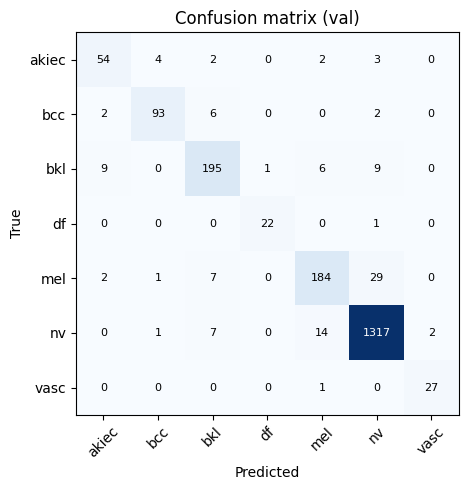

In [12]:
# ==============================================================================
# CELL 12: Reload best model, evaluate, save report + plots
# ==============================================================================
import json, os
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

CKPT = "/kaggle/working/checkpoints/best_model.pth"
print("best_model.pth exists:", os.path.exists(CKPT))
assert os.path.exists(CKPT), "Checkpoint is gone. Use the saved version's Output tab instead."

model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
model.eval()

def predict(loader, tta=False):
    probs_all, gts = [], []
    with torch.no_grad():
        for xa, xb, y in loader:
            xa, xb = xa.to(DEVICE), xb.to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16):
                p = model(xa, xb).softmax(1)
                if tta:
                    p = p + model(xa.flip(3), xb.flip(3)).softmax(1)
                    p = p + model(xa.flip(2), xb.flip(2)).softmax(1)
                    p = p / 3
            probs_all.append(p.float().cpu()); gts.extend(y.tolist())
    return torch.cat(probs_all).numpy(), np.array(gts)

for tta in [False, True]:
    probs, gts = predict(val_loader, tta)
    preds = probs.argmax(1)
    print(f"\n=== TTA={tta} ===  acc {accuracy_score(gts, preds):.4f} | "
          f"macro-F1 {f1_score(gts, preds, average='macro'):.4f} | "
          f"weighted-F1 {f1_score(gts, preds, average='weighted'):.4f}")

print("\n", classification_report(gts, preds, target_names=CLASSES, digits=3))
cm = confusion_matrix(gts, preds)
mel = CLASS_TO_IDX['mel']
print("Melanoma recall:", round(cm[mel, mel] / cm[mel].sum(), 3))

# ---- confusion matrix plot ----
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=45)
ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
for i in range(7):
    for j in range(7):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion matrix (val)')
plt.tight_layout(); plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150); plt.show()

# ---- training curves ----
hp = "/kaggle/working/checkpoints/history.json"
if os.path.exists(hp):
    h = json.load(open(hp))
    ep = [r['epoch'] for r in h]
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(ep, [r['train_acc'] for r in h], label='train acc')
    axs[0].plot(ep, [r['val_acc'] for r in h], label='val acc')
    axs[0].plot(ep, [r['val_f1m'] for r in h], label='val macro-F1'); axs[0].legend(); axs[0].set_title('Accuracy / F1')
    axs[1].plot(ep, [r['train_loss'] for r in h], label='train loss')
    axs[1].plot(ep, [r['val_loss'] for r in h], label='val loss'); axs[1].legend(); axs[1].set_title('Loss')
    plt.tight_layout(); plt.savefig('/kaggle/working/training_curves.png', dpi=150); plt.show()


In [14]:
# ==============================================================================
# CELL 13: Safety guardrail (confidence/entropy) + risk-based triage
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score

CKPT = "/kaggle/working/checkpoints/best_model.pth"
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
model.eval()

# ---- 1. probabilities on the validation set (no TTA, it did not help) ----
probs_l, gts_l = [], []
with torch.no_grad():
    for xa, xb, y in val_loader:
        with torch.autocast('cuda', dtype=torch.float16):
            p = model(xa.to(DEVICE), xb.to(DEVICE)).softmax(1)
        probs_l.append(p.float().cpu()); gts_l.extend(y.tolist())
probs = torch.cat(probs_l).numpy()
gts = np.array(gts_l)
preds = probs.argmax(1)
conf = probs.max(1)
entropy = -(probs * np.log(probs + 1e-12)).sum(1) / np.log(len(CLASSES))   # 0..1
MEL = CLASS_TO_IDX['mel']

# ---- 2. guardrail settings (from your diagram) ----
CONF_T = 0.60        # confidence below this -> Unknown
ENT_T = 0.60         # normalized entropy above this -> Unknown
MEL_ESCALATE = 0.20  # predicted benign but P(mel) >= this -> Moderate

def guardrail(conf, ent, conf_t=CONF_T, ent_t=ENT_T):
    return (conf < conf_t) | (ent > ent_t)          # True = Unknown

# ---- 3. sweep thresholds to see the accuracy / coverage trade-off ----
rows = []
for ct in [0.50, 0.60, 0.70, 0.80]:
    unk = guardrail(conf, entropy, ct, ENT_T)
    keep = ~unk
    rows.append(dict(conf_thr=ct, unknown_pct=round(unk.mean() * 100, 1),
                     acc_on_accepted=round(accuracy_score(gts[keep], preds[keep]) * 100, 2),
                     mel_errors_caught=int(((gts == MEL) & (preds != MEL) & unk).sum())))
print("Threshold sweep (entropy threshold fixed at %.2f):" % ENT_T)
print(pd.DataFrame(rows).to_string(index=False))

# ---- 4. apply the chosen guardrail ----
unknown = guardrail(conf, entropy)
keep = ~unknown
print(f"\nChosen guardrail: conf < {CONF_T} or entropy > {ENT_T}")
print(f"Unknown (sent for expert review): {unknown.sum()} / {len(gts)} ({unknown.mean()*100:.1f}%)")
print(f"Accuracy overall          : {accuracy_score(gts, preds)*100:.2f}%")
print(f"Accuracy on accepted cases: {accuracy_score(gts[keep], preds[keep])*100:.2f}% "
      f"(coverage {keep.mean()*100:.1f}%)")
wrong = preds != gts
print(f"Wrong predictions caught by the guardrail: {(wrong & unknown).sum()} of {wrong.sum()}")

# ---- 5. risk-based triage ----
RISK_OF_CLASS = {'mel': 'High', 'bcc': 'High', 'akiec': 'Moderate',
                 'bkl': 'Low', 'nv': 'Low', 'df': 'Low', 'vasc': 'Low'}

def triage(pred_idx, unk, p_mel):
    if unk:
        return 'Unknown'                       # refer to dermatologist
    risk = RISK_OF_CLASS[CLASSES[pred_idx]]
    if risk == 'Low' and p_mel >= MEL_ESCALATE:
        return 'Moderate'                      # safety escalation
    return risk

risk = np.array([triage(p, u, pm) for p, u, pm in zip(preds, unknown, probs[:, MEL])])

res = pd.DataFrame({'true': [CLASSES[i] for i in gts], 'pred': [CLASSES[i] for i in preds],
                    'conf': conf.round(3), 'entropy': entropy.round(3), 'risk': risk})
order = ['High', 'Moderate', 'Low', 'Unknown']
print("\nTrue class vs assigned risk level:")
print(pd.crosstab(res['true'], res['risk'])[[c for c in order if c in set(risk)]].to_string())

# ---- 6. melanoma safety ----
is_mel = gts == MEL
mel_flagged = is_mel & (risk != 'Low')
print("\nMelanoma safety:")
print(f"  Melanoma recall (classifier alone)   : {(preds[is_mel] == MEL).mean():.3f}")
print(f"  Melanoma sensitivity with triage     : {mel_flagged.sum() / is_mel.sum():.3f} "
      f"(flagged High / Moderate / Unknown)")
print(f"  Melanomas still labelled Low risk    : {(is_mel & (risk == 'Low')).sum()} of {is_mel.sum()}")
print(f"  Benign cases sent to review (cost)   : {((~is_mel) & (risk != 'Low')).sum()} of {(~is_mel).sum()}")

res.to_csv('/kaggle/working/triage_results.csv', index=False)
np.save('/kaggle/working/val_probs.npy', probs)
print("\nSaved triage_results.csv and val_probs.npy")

Threshold sweep (entropy threshold fixed at 0.60):
 conf_thr  unknown_pct  acc_on_accepted  mel_errors_caught
      0.5          2.5            95.80                  6
      0.6          2.6            95.85                  6
      0.7          3.7            96.11                  8
      0.8          6.4            96.64                 12

Chosen guardrail: conf < 0.6 or entropy > 0.6
Unknown (sent for expert review): 52 / 2003 (2.6%)
Accuracy overall          : 94.56%
Accuracy on accepted cases: 95.85% (coverage 97.4%)
Wrong predictions caught by the guardrail: 28 of 109

True class vs assigned risk level:
risk   High  Moderate   Low  Unknown
true                                
akiec     4        51     3        7
bcc      92         1     5        5
bkl       4         7   195       14
df        0         0    23        0
mel     179         2    29       13
nv       11         2  1315       13
vasc      1         0    27        0

Melanoma safety:
  Melanoma recall (classifier

In [15]:
# ==============================================================================
# CELL 13b: Sweep MEL_ESCALATE (uses variables already in memory)
# ==============================================================================
benign_idx = [CLASS_TO_IDX[c] for c in ['nv', 'bkl', 'df', 'vasc']]
is_benign = np.isin(gts, benign_idx)
rows = []
for t in [0.50, 0.20, 0.10, 0.05, 0.03, 0.02, 0.01]:
    r = np.array([triage(p, u, pm) for p, u, pm in zip(preds, unknown, probs[:, MEL])]) \
        if False else None
    MEL_ESCALATE = t
    r = np.array([triage(p, u, pm) for p, u, pm in zip(preds, unknown, probs[:, MEL])])
    rows.append(dict(mel_escalate=t,
                     mel_sensitivity=round((is_mel & (r != 'Low')).sum() / is_mel.sum(), 3),
                     mel_still_low=int((is_mel & (r == 'Low')).sum()),
                     true_benign_flagged=int((is_benign & (r != 'Low')).sum()),
                     benign_flagged_pct=round((is_benign & (r != 'Low')).sum() / is_benign.sum() * 100, 1)))
print(pd.DataFrame(rows).to_string(index=False))
MEL_ESCALATE = 0.20   # reset to the default
print("Cell 13b executed successfully!")

 mel_escalate  mel_sensitivity  mel_still_low  true_benign_flagged  benign_flagged_pct
         0.50            0.865             30                   50                 3.1
         0.20            0.870             29                   52                 3.2
         0.10            0.883             26                   63                 3.9
         0.05            0.888             25                   80                 5.0
         0.03            0.888             25                  112                 6.9
         0.02            0.928             16                  159                 9.9
         0.01            0.996              1                 1581                98.1
Cell 13b executed successfully!


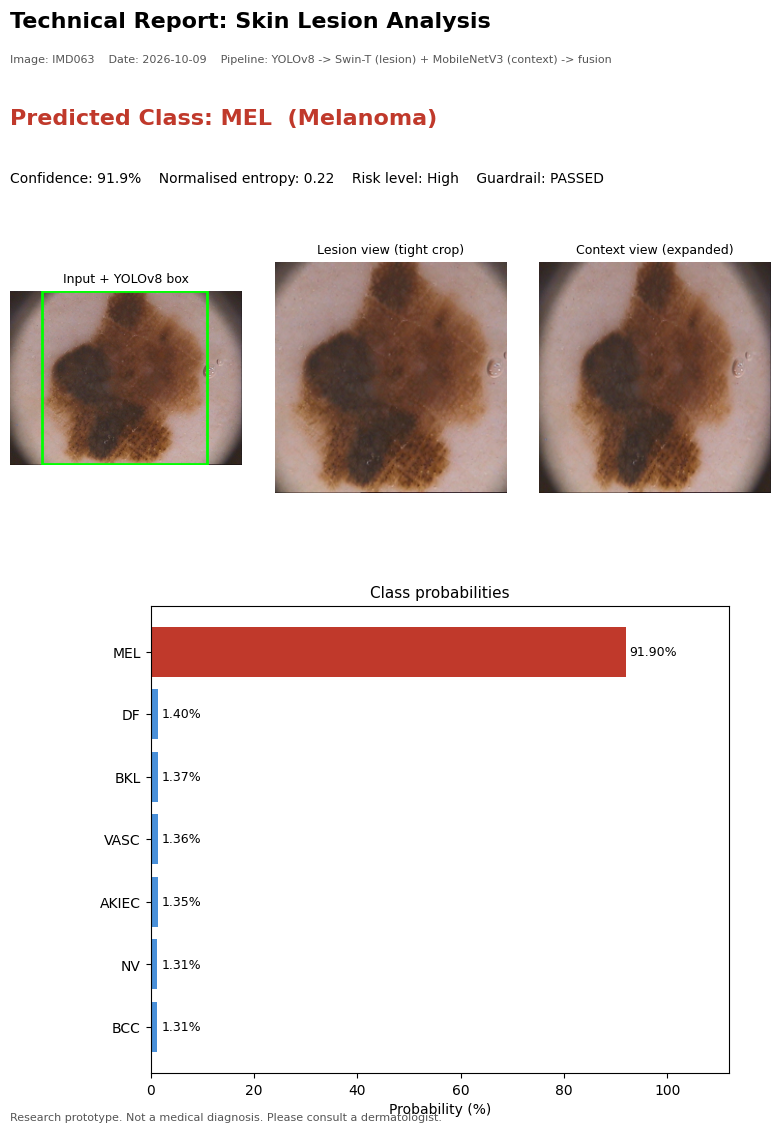

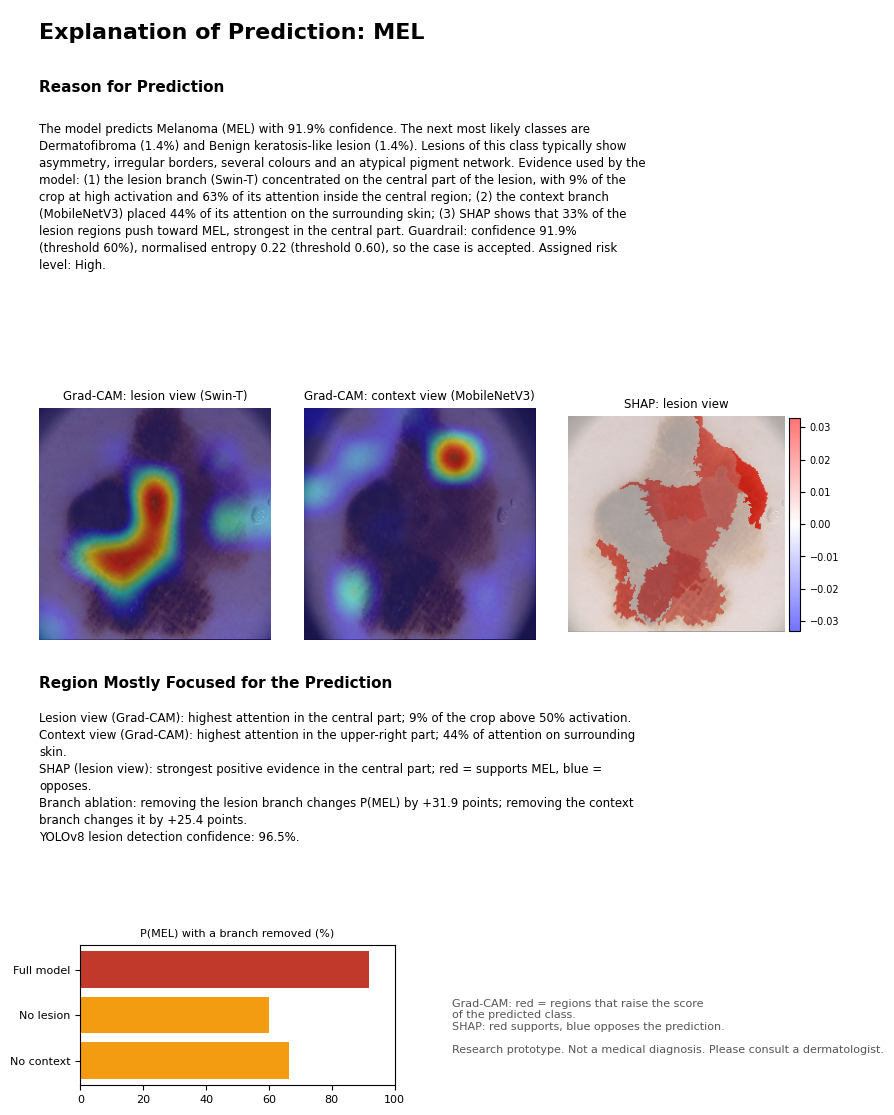

Predicted: MEL (91.9%) | risk: High
Saved PDF: /kaggle/working/technical_report_IMD063.pdf


In [34]:
# ==============================================================================
# CELL 15: Technical report PDF (prediction, reason, Grad-CAM, SHAP, probabilities)
# ==============================================================================
import os, subprocess, sys, textwrap, datetime
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
import torchvision.transforms.functional as TF
from PIL import Image
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap
from skimage.segmentation import slic
from ultralytics import YOLO

# ------------------------------- SETTINGS -------------------------------------
TEST_IMAGE = "/kaggle/input/datasets/athina123/ph2dataset/ph2_dataset/trainx/IMD063.bmp"    # <-- change to your own test image path
CKPT = "/kaggle/working/checkpoints/best_model.pth"
BEST_PT = "/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"
CONF_T, ENT_T, MEL_ESCALATE = 0.60, 0.60, 0.02
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SHAP_SEGMENTS, SHAP_SAMPLES = 40, 500
RISK_OF_CLASS = {'mel': 'High', 'bcc': 'High', 'akiec': 'Moderate',
                 'bkl': 'Low', 'nv': 'Low', 'df': 'Low', 'vasc': 'Low'}
FULL_NAME = {'akiec': 'Actinic keratosis / intraepithelial carcinoma', 'bcc': 'Basal cell carcinoma',
             'bkl': 'Benign keratosis-like lesion', 'df': 'Dermatofibroma',
             'mel': 'Melanoma', 'nv': 'Melanocytic nevus (mole)', 'vasc': 'Vascular lesion'}
CLASS_FEATURES = {
    'akiec': "scaly or rough surface, pink-red areas and irregular borders",
    'bcc': "pink or pearly areas, fine branching vessels and possible ulceration",
    'bkl': "sharply demarcated borders, waxy 'stuck-on' texture and milia-like cysts",
    'df': "a central whitish scar-like area surrounded by a delicate pigment network",
    'mel': "asymmetry, irregular borders, several colours and an atypical pigment network",
    'nv': "a symmetric shape, uniform colour and a regular pigment network",
    'vasc': "red, purple or maroon lagoon-like areas"}
DISCLAIMER = "Research prototype. Not a medical diagnosis. Please consult a dermatologist."

# ------------------------------- LOAD MODELS ----------------------------------
model.load_state_dict(torch.load(CKPT, map_location=DEVICE)); model.eval()
det = YOLO(BEST_PT)
MEL = CLASS_TO_IDX['mel']

def square_crop(img, cx, cy, w, h, scale, out=256):
    H, W = img.shape[:2]
    side = max(w, h) * scale
    x1, x2 = int(max(0, cx - side / 2)), int(min(W, cx + side / 2))
    y1, y2 = int(max(0, cy - side / 2)), int(min(H, cy + side / 2))
    return cv2.resize(img[y1:y2, x1:x2], (out, out), interpolation=cv2.INTER_AREA)

def to_tensor(rgb):
    return TF.normalize(TF.to_tensor(Image.fromarray(rgb)), IMNET_MEAN, IMNET_STD)

# ------------------------------- 1. DETECT + CROP -----------------------------
img_bgr = cv2.imread(TEST_IMAGE); H, W = img_bgr.shape[:2]
r = det.predict(TEST_IMAGE, imgsz=384, conf=0.25, device=0, verbose=False)[0]
if len(r.boxes) > 0:
    k = int(r.boxes.conf.argmax())
    cx, cy, bw, bh = r.boxes.xywh[k].cpu().numpy().tolist()
    det_conf = float(r.boxes.conf[k])
else:
    cx, cy, bw, bh, det_conf = W / 2, H / 2, W, H, 0.0
def crop_rgb(scale):
    c = cv2.cvtColor(square_crop(img_bgr, cx, cy, bw, bh, scale), cv2.COLOR_BGR2RGB)
    return np.array(Image.fromarray(c).resize((224, 224)))
les_rgb, ctx_rgb = crop_rgb(1.1), crop_rgb(1.6)
xa = to_tensor(les_rgb).unsqueeze(0).to(DEVICE)
xb = to_tensor(ctx_rgb).unsqueeze(0).to(DEVICE)

# ------------------------------- 2. PREDICT -----------------------------------
def forward_feats(xa, xb, zero=None):
    fa = model.lesion_net.forward_features(xa)
    fb = model.context_net.forward_features(xb)
    if fa.requires_grad: fa.retain_grad()
    if fb.requires_grad: fb.retain_grad()
    pl = model.proj_l(model.lesion_net.forward_head(fa))
    pc = model.proj_c(model.context_net.forward_head(fb))
    if zero == 'lesion': pl = torch.zeros_like(pl)
    if zero == 'context': pc = torch.zeros_like(pc)
    return model.head(torch.cat([pl, pc], 1)), fa, fb

with torch.no_grad():
    probs = forward_feats(xa, xb)[0].softmax(1)[0].cpu().numpy()
    p_no_les = forward_feats(xa, xb, 'lesion')[0].softmax(1)[0].cpu().numpy()
    p_no_ctx = forward_feats(xa, xb, 'context')[0].softmax(1)[0].cpu().numpy()
cls = int(probs.argmax()); conf = float(probs[cls]); pname = CLASSES[cls]
entropy = float(-(probs * np.log(probs + 1e-12)).sum() / np.log(len(CLASSES)))
unknown = (conf < CONF_T) or (entropy > ENT_T)
if unknown: risk = 'Unknown'
else:
    risk = RISK_OF_CLASS[pname]
    if risk == 'Low' and probs[MEL] >= MEL_ESCALATE: risk = 'Moderate'
top3 = np.argsort(-probs)[:3]

# ------------------------------- 3. GRAD-CAM ----------------------------------
with torch.enable_grad():
    logits, fa, fb = forward_feats(xa, xb)
    model.zero_grad(); logits[0, cls].backward()
def make_cam(f):
    with torch.no_grad():
        g = f.grad
        if f.shape[-1] > f.shape[1]:           # NHWC (Swin)
            cam = ((g.mean((1, 2), keepdim=True) * f).sum(-1))[0]
        else:                                   # NCHW (MobileNet)
            cam = ((g.mean((2, 3), keepdim=True) * f).sum(1))[0]
        cam = torch.relu(cam).cpu().numpy()
    cam = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_CUBIC)
    cam = np.clip(cam, 0, None)
    return cam / cam.max() if cam.max() > 0 else cam
cam_les, cam_ctx = make_cam(fa), make_cam(fb)

def overlay(rgb, cam, alpha=0.45):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[:, :, ::-1]
    return np.uint8((1 - alpha) * rgb + alpha * heat)

# ------------------------------- 4. SHAP (superpixels, lesion view) -----------
segments = slic(les_rgb, n_segments=SHAP_SEGMENTS, compactness=10, start_label=0)
nseg = int(segments.max()) + 1
fill = les_rgb.mean((0, 1))
def f_shap(z):
    z = np.atleast_2d(z); out = []
    for i in range(0, len(z), 64):
        imgs = []
        for row in z[i:i + 64]:
            im = les_rgb.copy()
            im[np.isin(segments, np.where(row == 0)[0])] = fill
            imgs.append(to_tensor(im))
        t = torch.stack(imgs).to(DEVICE)
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
            lg = model(t, xb.repeat(len(imgs), 1, 1, 1))
        out.append(lg.float().softmax(1)[:, cls].cpu().numpy())
    return np.concatenate(out)
expl = shap.KernelExplainer(f_shap, np.zeros((1, nseg)))
sv = np.array(expl.shap_values(np.ones((1, nseg)), nsamples=SHAP_SAMPLES, silent=True)).reshape(-1)[:nseg]
shap_map = sv[segments]
vmax = max(np.abs(sv).max(), 1e-6)

# ------------------------------- 5. REGION ANALYSIS ---------------------------
def where(mask):
    ys, xs = np.nonzero(mask)
    if len(ys) == 0: return "no distinct area"
    cy_, cx_ = ys.mean() / mask.shape[0], xs.mean() / mask.shape[1]
    rr = "upper" if cy_ < 0.38 else "lower" if cy_ > 0.62 else "middle"
    cc = "left" if cx_ < 0.38 else "right" if cx_ > 0.62 else "centre"
    return "central part" if (rr == "middle" and cc == "centre") else f"{rr}-{cc} part"

hot_les = cam_les >= 0.5
area_les = hot_les.mean() * 100
centre_share = cam_les[56:168, 56:168].sum() / max(cam_les.sum(), 1e-9) * 100
loc_les = where(hot_les)
out_frac = (1 - cam_ctx[35:189, 35:189].sum() / max(cam_ctx.sum(), 1e-9)) * 100
loc_ctx = where(cam_ctx >= 0.5)
pos_pct = (sv > 0).mean() * 100
loc_shap = where(shap_map >= 0.5 * shap_map.max()) if shap_map.max() > 0 else "no distinct area"
d_les = probs[cls] - p_no_les[cls]; d_ctx = probs[cls] - p_no_ctx[cls]

# ------------------------------- 6. REASON TEXT -------------------------------
second, third = top3[1], top3[2]
reason = (
    f"The model predicts {FULL_NAME[pname]} ({pname.upper()}) with {conf*100:.1f}% confidence. "
    f"The next most likely classes are {FULL_NAME[CLASSES[second]]} ({probs[second]*100:.1f}%) and "
    f"{FULL_NAME[CLASSES[third]]} ({probs[third]*100:.1f}%). "
    f"Lesions of this class typically show {CLASS_FEATURES[pname]}. "
    f"Evidence used by the model: (1) the lesion branch (Swin-T) concentrated on the {loc_les} of the lesion, "
    f"with {area_les:.0f}% of the crop at high activation and {centre_share:.0f}% of its attention inside the "
    f"central region; (2) the context branch (MobileNetV3) placed {out_frac:.0f}% of its attention on the "
    f"surrounding skin; (3) SHAP shows that {pos_pct:.0f}% of the lesion regions push toward {pname.upper()}, "
    f"strongest in the {loc_shap}. "
    f"Guardrail: confidence {conf*100:.1f}% (threshold {CONF_T*100:.0f}%), normalised entropy {entropy:.2f} "
    f"(threshold {ENT_T:.2f}), so the case is {'sent to Unknown for expert review' if unknown else 'accepted'}. "
    f"Assigned risk level: {risk}."
)
region = (
    f"Lesion view (Grad-CAM): highest attention in the {loc_les}; {area_les:.0f}% of the crop above 50% activation.\n"
    f"Context view (Grad-CAM): highest attention in the {loc_ctx}; {out_frac:.0f}% of attention on surrounding skin.\n"
    f"SHAP (lesion view): strongest positive evidence in the {loc_shap}; red = supports {pname.upper()}, blue = opposes.\n"
    f"Branch ablation: removing the lesion branch changes P({pname.upper()}) by {d_les*100:+.1f} points; "
    f"removing the context branch changes it by {d_ctx*100:+.1f} points.\n"
    f"YOLOv8 lesion detection confidence: {det_conf*100:.1f}%."
)
def put_text(ax, title, body, width=100, size=8.5):
    ax.axis('off')
    ax.text(0, 1, title, fontsize=11, fontweight='bold', va='top', transform=ax.transAxes)
    wrapped = "\n".join(textwrap.fill(p, width) for p in body.split("\n"))
    ax.text(0, 0.84, wrapped, fontsize=size, va='top', transform=ax.transAxes, linespacing=1.4)

# ------------------------------- 7. BUILD PDF ---------------------------------
img_id = os.path.splitext(os.path.basename(TEST_IMAGE))[0]
OUT_PDF = f"/kaggle/working/technical_report_{img_id}.pdf"
RISK_COL = {'High': '#c0392b', 'Moderate': '#e67e22', 'Low': '#27ae60', 'Unknown': '#7f8c8d'}

with PdfPages(OUT_PDF) as pdf:
    # ---- page 1 ----
    fig = plt.figure(figsize=(8.27, 11.69))
    ax = fig.add_axes([0.05, 0.93, 0.9, 0.05]); ax.axis('off')
    ax.text(0, 0.7, "Technical Report: Skin Lesion Analysis", fontsize=16, fontweight='bold')
    ax.text(0, 0.1, f"Image: {img_id}    Date: {datetime.date.today()}    "
            "Pipeline: YOLOv8 -> Swin-T (lesion) + MobileNetV3 (context) -> fusion", fontsize=8, color='#555')
    ax = fig.add_axes([0.05, 0.82, 0.9, 0.10]); ax.axis('off')
    ax.text(0, 0.62, f"Predicted Class: {pname.upper()}  ({FULL_NAME[pname]})", fontsize=16,
            fontweight='bold', color=RISK_COL[risk])
    ax.text(0, 0.12, f"Confidence: {conf*100:.1f}%    Normalised entropy: {entropy:.2f}    "
            f"Risk level: {risk}    Guardrail: {'UNKNOWN' if unknown else 'PASSED'}", fontsize=10)
    for j, (im, t) in enumerate([(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), "Input + YOLOv8 box"),
                                 (les_rgb, "Lesion view (tight crop)"), (ctx_rgb, "Context view (expanded)")]):
        a = fig.add_axes([0.05 + j * 0.32, 0.54, 0.28, 0.25]); a.imshow(im); a.axis('off'); a.set_title(t, fontsize=9)
        if j == 0:
            a.add_patch(Rectangle((cx - bw / 2, cy - bh / 2), bw, bh, fill=False, ec='lime', lw=2))
    a = fig.add_axes([0.22, 0.07, 0.70, 0.40])
    order = np.argsort(probs)
    bars = a.barh([CLASSES[i].upper() for i in order], probs[order] * 100,
                  color=[RISK_COL[risk] if i == cls else '#4a90d9' for i in order])
    for b, v in zip(bars, probs[order] * 100):
        a.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.2f}%", va='center', fontsize=9)
    a.set_xlim(0, 112); a.set_xlabel("Probability (%)"); a.set_title("Class probabilities", fontsize=11)
    fig.text(0.05, 0.03, DISCLAIMER, fontsize=8, color='#555')
    pdf.savefig(fig); plt.show()

    # ---- page 2 ----
    fig = plt.figure(figsize=(8.27, 11.69))
    ax = fig.add_axes([0.05, 0.93, 0.9, 0.05]); ax.axis('off')
    ax.text(0, 0.5, f"Explanation of Prediction: {pname.upper()}", fontsize=16, fontweight='bold')
    put_text(fig.add_axes([0.05, 0.69, 0.9, 0.23]), "Reason for Prediction", reason)
    panels = [(overlay(les_rgb, cam_les), "Grad-CAM: lesion view (Swin-T)"),
              (overlay(ctx_rgb, cam_ctx), "Grad-CAM: context view (MobileNetV3)"), (None, "SHAP: lesion view")]
    for j, (im, t) in enumerate(panels):
        a = fig.add_axes([0.05 + j * 0.32, 0.43, 0.28, 0.22]); a.axis('off'); a.set_title(t, fontsize=8.5)
        if im is not None: a.imshow(im)
        else:
            a.imshow(les_rgb); m = a.imshow(shap_map, cmap='bwr', vmin=-vmax, vmax=vmax, alpha=0.55)
            cb = fig.colorbar(m, ax=a, fraction=0.046, pad=0.02); cb.ax.tick_params(labelsize=7)
    put_text(fig.add_axes([0.05, 0.22, 0.9, 0.19]), "Region Mostly Focused for the Prediction", region)
    a = fig.add_axes([0.10, 0.06, 0.38, 0.12])
    a.barh(["No context", "No lesion", "Full model"], [p_no_ctx[cls] * 100, p_no_les[cls] * 100, conf * 100],
           color=['#f39c12', '#f39c12', RISK_COL[risk]])
    a.set_xlim(0, 100); a.set_title(f"P({pname.upper()}) with a branch removed (%)", fontsize=8)
    a.tick_params(labelsize=8)
    fig.text(0.55, 0.11, "Grad-CAM: red = regions that raise the score\nof the predicted class.\n"
             "SHAP: red supports, blue opposes the prediction.\n\n" + DISCLAIMER, fontsize=8, color='#555', va='center')
    pdf.savefig(fig); plt.show()

print("Predicted:", pname.upper(), f"({conf*100:.1f}%) | risk:", risk)
print("Saved PDF:", OUT_PDF)

In [16]:
import glob
hits = []
for ext in ['jpg', 'jpeg', 'png']:
    hits += glob.glob(f'/kaggle/input/**/*.{ext}', recursive=True)
hits = [h for h in hits if 'ham10000' not in h.lower() and 'ISIC_' not in h]
print("\n".join(hits[:20]) if hits else "No test image found. Check the dataset is attached, then restart the session.")

/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/val_batch0_pred.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/train_batch25050.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/val_batch1_pred.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/val_batch2_labels.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/labels.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/train_batch2.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/val_batch2_pred.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/train_batch1.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/train_batch0.jpg
/kaggle/input/notebooks/srini0912/notebookc4b5b97c6b/yolo_runs/lesion_detection/val_batch1_labels.jpg
/kaggle/input

In [24]:
# ==============================================================================
# CELL 15b-1: One-time setup (models, helpers). Run once per session.
# ==============================================================================
import os, subprocess, sys, textwrap, datetime
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
import torchvision.transforms.functional as TF
from PIL import Image
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap
from skimage.segmentation import slic
from ultralytics import YOLO

CKPT = "/kaggle/working/checkpoints/best_model.pth"
BEST_PT = "/kaggle/working/yolo_runs/lesion_detection/weights/best.pt"
CONF_T, ENT_T, MAL_ESCALATE = 0.60, 0.60, 0.05      # MAL = P(mel)+P(bcc)+P(akiec)
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SHAP_SEGMENTS, SHAP_SAMPLES = 40, 500
RISK_OF_CLASS = {'mel': 'High', 'bcc': 'High', 'akiec': 'Moderate',
                 'bkl': 'Low', 'nv': 'Low', 'df': 'Low', 'vasc': 'Low'}
FULL_NAME = {'akiec': 'Actinic keratosis / intraepithelial carcinoma', 'bcc': 'Basal cell carcinoma',
             'bkl': 'Benign keratosis-like lesion', 'df': 'Dermatofibroma',
             'mel': 'Melanoma', 'nv': 'Melanocytic nevus (mole)', 'vasc': 'Vascular lesion'}
CLASS_FEATURES = {
    'akiec': "scaly or rough surface, pink-red areas and irregular borders",
    'bcc': "pink or pearly areas, fine branching vessels and possible ulceration",
    'bkl': "sharply demarcated borders, waxy 'stuck-on' texture and milia-like cysts",
    'df': "a central whitish scar-like area surrounded by a delicate pigment network",
    'mel': "asymmetry, irregular borders, several colours and an atypical pigment network",
    'nv': "a symmetric shape, uniform colour and a regular pigment network",
    'vasc': "red, purple or maroon lagoon-like areas"}
DISCLAIMER = "Research prototype. Not a medical diagnosis. Please consult a dermatologist."
RISK_COL = {'High': '#c0392b', 'Moderate': '#e67e22', 'Low': '#27ae60', 'Unknown': '#7f8c8d'}
MEL = CLASS_TO_IDX['mel']
MAL_IDX = [CLASS_TO_IDX[c] for c in ['mel', 'bcc', 'akiec']]

model.load_state_dict(torch.load(CKPT, map_location=DEVICE)); model.eval()
det = YOLO(BEST_PT)
print("Setup done. Now run Cell 15b-2 and call make_report(path, true_class).")
print("make_report() ready.")

Setup done. Now run Cell 15b-2 and call make_report(path, true_class).
make_report() ready.


In [27]:
print('model' in globals(), 'CLASSES' in globals(), 'det' in globals(), 'CONF_T' in globals())

True True True True


In [30]:
import shutil, os
shutil.rmtree('/kaggle/working/crops', ignore_errors=True)
shutil.rmtree('/kaggle/working/yolo_dataset', ignore_errors=True)
if os.path.exists('/kaggle/working/crops_backup.zip'):
    os.remove('/kaggle/working/crops_backup.zip')

In [36]:
import shutil, os, gc
shutil.rmtree('/kaggle/working/yolo_dataset', ignore_errors=True)
if os.path.exists('/kaggle/working/crops_backup.zip'):
    os.remove('/kaggle/working/crops_backup.zip')
gc.collect()

44377

In [40]:
# ==============================================================================
# CELL 18: Cache full images and YOLO lesion crops as 224x224 uint8 arrays
# ==============================================================================
import os, numpy as np, cv2
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

assert 'lesion_path' in train_df.columns and os.path.exists(train_df['lesion_path'].iloc[0]), \
    "Crops missing. Run Cell 8 first."

CACHE = "/kaggle/temp/cache"
os.makedirs(CACHE, exist_ok=True)

def load224(p):
    im = cv2.imread(p)
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    return cv2.resize(im, (224, 224), interpolation=cv2.INTER_AREA)

def build(df, col, name):
    out = f"{CACHE}/{name}.npy"
    if os.path.exists(out):
        print("exists:", name); return
    with ThreadPoolExecutor(4) as ex:
        arr = np.stack(list(tqdm(ex.map(load224, df[col].tolist()),
                                 total=len(df), desc=name)))
    np.save(out, arr)
    print(name, arr.shape, f"{arr.nbytes/1e9:.2f} GB")

build(train_df, 'image_path',  'train_full')
build(val_df,   'image_path',  'val_full')
build(train_df, 'lesion_path', 'train_lesion')
build(val_df,   'lesion_path', 'val_lesion')

y_train = train_df['dx'].map(CLASS_TO_IDX).values
y_val   = val_df['dx'].map(CLASS_TO_IDX).values
np.save(f"{CACHE}/y_train.npy", y_train); np.save(f"{CACHE}/y_val.npy", y_val)
print("Labels:", y_train.shape, y_val.shape)

exists: train_full
exists: val_full
exists: train_lesion
exists: val_lesion
Labels: (8012,) (2003,)


In [42]:
# ==============================================================================
# CELL 19: Model zoo (8 backbones + paper head) and resumable training function
# ==============================================================================
import os, json, time, gc, math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import timm, torchvision
from sklearn.metrics import f1_score, accuracy_score, matthews_corrcoef

CACHE = "/kaggle/temp/cache"
OUT   = "/kaggle/working/zoo"; os.makedirs(OUT, exist_ok=True)   # persists after the session
DEV   = "cuda"
EPOCHS, BATCH, PATIENCE, NUM_CLASSES = 15, 32, 6, 7
LR_DEFAULT, LR = 5e-5, {'alexnet': 1e-4}
MODELS   = ['vit','inceptionv3','vgg16','resnet50','densenet121','xception','mobilenetv2','alexnet']
VIEWS    = ['full','lesion']                     # full image vs YOLO crop
ALL_RUNS = [(m, v) for m in MODELS for v in VIEWS]

# Paper Table 5 (ratio thresholding): repeat factors per class
FACTORS = {'mel':3,'nv':1,'bcc':6,'akiec':10,'bkl':3,'df':17,'vasc':14}
FAC_BY_IDX = {idx: FACTORS[name.lower()] for name, idx in CLASS_TO_IDX.items()}

MEAN = torch.tensor([0.485,0.456,0.406], device=DEV).view(1,3,1,1)
STD  = torch.tensor([0.229,0.224,0.225], device=DEV).view(1,3,1,1)
torch.backends.cudnn.benchmark = True

# ---------------- head from the paper: SepConv(3x3,2048) -> BN -> GAP -> Dense(7) ----------------
class SepHead(nn.Module):
    def __init__(s, c, n=NUM_CLASSES, w=2048):
        super().__init__()
        s.dw = nn.Conv2d(c, c, 3, padding=1, groups=c)
        s.pw = nn.Conv2d(c, w, 1)
        s.bn = nn.BatchNorm2d(w)
        s.fc = nn.Linear(w, n)
    def forward(s, x):
        return s.fc(s.bn(s.pw(s.dw(x))).mean((2, 3)))

def build_backbone(name):
    tv = torchvision.models
    if name == 'vit':
        return timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0), True
    if name == 'inceptionv3':
        return timm.create_model('inception_v3', pretrained=True, num_classes=0, global_pool=''), False
    if name == 'xception':
        err = None
        for n in ('legacy_xception', 'xception'):
            try: return timm.create_model(n, pretrained=True, num_classes=0, global_pool=''), False
            except Exception as e: err = e
        raise err
    if name == 'vgg16':       return tv.vgg16(weights='DEFAULT').features, False
    if name == 'alexnet':     return tv.alexnet(weights='DEFAULT').features, False
    if name == 'resnet50':    return nn.Sequential(*list(tv.resnet50(weights='DEFAULT').children())[:-2]), False
    if name == 'densenet121': return nn.Sequential(tv.densenet121(weights='DEFAULT').features, nn.ReLU()), False
    if name == 'mobilenetv2': return tv.mobilenet_v2(weights='DEFAULT').features, False
    raise ValueError(name)

class Net(nn.Module):
    def __init__(s, name):
        super().__init__()
        s.backbone, s.vit = build_backbone(name)
        s.backbone.eval()
        with torch.no_grad():
            c = s._feat(torch.zeros(1, 3, 224, 224)).shape[1]
        s.head = SepHead(c)
    def _feat(s, x):
        if s.vit:                                   # tokens -> 14x14 feature map (drop CLS)
            t = s.backbone.forward_features(x)[:, 1:]
            B, N, C = t.shape; g = int(N ** 0.5)
            return t.transpose(1, 2).reshape(B, C, g, g)
        return s.backbone(x)
    def forward(s, x):
        return s.head(s._feat(x))

# ---------------- data helpers (uint8 arrays in RAM, augmentation on GPU) ----------------
def to_gpu(a):
    return torch.from_numpy(a).to(DEV, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)

def gpu_aug(x):
    B = x.shape[0]
    m = (torch.rand(B, device=DEV) < 0.5).view(B, 1, 1, 1); x = torch.where(m, x.flip(3), x)
    m = (torch.rand(B, device=DEV) < 0.5).view(B, 1, 1, 1); x = torch.where(m, x.flip(2), x)
    x = torch.rot90(x, int(np.random.randint(4)), dims=(2, 3))
    x = x * (1 + (torch.rand(B, 1, 1, 1, device=DEV) - 0.5) * 0.4)                    # brightness
    mu = x.mean((1, 2, 3), keepdim=True)
    x = (x - mu) * (1 + (torch.rand(B, 1, 1, 1, device=DEV) - 0.5) * 0.4) + mu        # contrast
    return x.clamp_(0, 1)

def epoch_indices(y, rng):
    idx = np.concatenate([np.repeat(np.where(y == c)[0], f) for c, f in FAC_BY_IDX.items()])
    rng.shuffle(idx); return idx

@torch.no_grad()
def predict(model, X, bs=64):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = (to_gpu(X[i:i+bs]) - MEAN) / STD
        with torch.autocast('cuda', dtype=torch.float16):
            lo = model(xb)
        out.append(F.softmax(lo.float(), 1).cpu().numpy())
    return np.concatenate(out)

# ---------------- one run: (model, view) -> json + best val probs ----------------
def run_one(name, view, epochs=EPOCHS, tag="", seed=42):
    key = f"{name}__{view}{tag}"
    jpath = f"{OUT}/{key}.json"
    if os.path.exists(jpath):
        print("skip (done):", key); return json.load(open(jpath))
    torch.manual_seed(seed); np.random.seed(seed); rng = np.random.default_rng(seed)
    Xtr = np.load(f"{CACHE}/train_{view}.npy"); Xva = np.load(f"{CACHE}/val_{view}.npy")
    ytr = np.load(f"{CACHE}/y_train.npy");      yva = np.load(f"{CACHE}/y_val.npy")

    model = Net(name).to(DEV)
    lr = LR.get(name, LR_DEFAULT)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    steps = math.ceil(len(epoch_indices(ytr, rng)) / BATCH) * epochs
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    scaler = torch.amp.GradScaler('cuda')
    print(f"\n=== {key} | lr {lr} | {epochs} epochs ===")

    best = dict(macro_f1=-1); hist = []; bad = 0; t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); idx = epoch_indices(ytr, rng); tl = tc = n = 0
        for i in range(0, len(idx), BATCH):
            b = idx[i:i+BATCH]
            xb = (gpu_aug(to_gpu(Xtr[b])) - MEAN) / STD
            yb = torch.from_numpy(ytr[b]).to(DEV)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(xb); loss = F.cross_entropy(lo, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(b); tc += (lo.argmax(1) == yb).sum().item(); n += len(b)
        probs = predict(model, Xva); pred = probs.argmax(1)
        m = dict(epoch=ep, train_loss=tl/n, train_acc=tc/n,
                 val_acc=float(accuracy_score(yva, pred)),
                 macro_f1=float(f1_score(yva, pred, average='macro')),
                 mcc=float(matthews_corrcoef(yva, pred)))
        hist.append(m)
        star = ""
        if m['macro_f1'] > best['macro_f1']:
            best = m; bad = 0; star = " *"
            np.save(f"{OUT}/{key}_valprobs.npy", probs)
        else:
            bad += 1
        print(f"  ep {ep:02d} | train {m['train_loss']:.3f}/{m['train_acc']:.3f} | "
              f"val acc {m['val_acc']:.4f} mF1 {m['macro_f1']:.4f} MCC {m['mcc']:.4f}{star}")
        if bad >= PATIENCE:
            print("  early stop"); break

    res = dict(key=key, model=name, view=view, lr=lr, best=best, history=hist,
               minutes=round((time.time() - t0) / 60, 1))
    json.dump(res, open(jpath, "w"))
    del model, opt, Xtr, Xva; gc.collect(); torch.cuda.empty_cache()
    return res

def summary_table():
    import pandas as pd
    rows = []
    for m, v in ALL_RUNS:
        p = f"{OUT}/{m}__{v}.json"
        if os.path.exists(p):
            r = json.load(open(p)); b = r['best']
            rows.append(dict(model=m, view=v, acc=b['val_acc'], macro_f1=b['macro_f1'],
                             mcc=b['mcc'], best_ep=b['epoch'], minutes=r['minutes']))
    return pd.DataFrame(rows).round(4)

print(f"{len(ALL_RUNS)} runs queued. Results go to {OUT} (re-running Cell 20 skips finished runs).")

16 runs queued. Results go to /kaggle/working/zoo (re-running Cell 20 skips finished runs).


In [44]:
import os, shutil
from IPython.display import FileLink, display

crop_dirs = sorted({os.path.dirname(p) for p in train_df['lesion_path'].tolist() + val_df['lesion_path'].tolist()})
CROP_DIR = os.path.commonpath(crop_dirs) if len(crop_dirs) > 1 else crop_dirs[0]
print("zipping:", CROP_DIR)

zip_path = shutil.make_archive("/kaggle/working/lesion_crops", "zip", CROP_DIR)
print(f"done: {zip_path}  ({os.path.getsize(zip_path)/1e9:.2f} GB)")
display(FileLink("lesion_crops.zip"))

zipping: /kaggle/working/crops/lesion
done: /kaggle/working/lesion_crops.zip  (0.19 GB)


/kaggle/working/lesion_crops.zip

In [45]:
import os, shutil
from IPython.display import FileLink, display

# 1) does the dataframe have a context path column?
print("columns:", [c for c in train_df.columns if 'path' in c.lower() or 'context' in c.lower()])

# 2) find folders named like "context" anywhere under /kaggle/working
hits = [os.path.join(r, d) for r, ds, _ in os.walk("/kaggle/working") for d in ds if 'context' in d.lower()]
print("context folders found:", hits)

# 3) zip the first match
if hits:
    ctx = hits[0]
    n = sum(len(f) for _, _, f in os.walk(ctx))
    print(f"zipping {ctx} ({n} files)")
    z = shutil.make_archive("/kaggle/working/context_crops", "zip", ctx)
    print(f"done: {os.path.getsize(z)/1e9:.2f} GB")
    display(FileLink("context_crops.zip"))
else:
    print("No folder named 'context' found.")

columns: ['image_path', 'lesion_path', 'context_path']
context folders found: ['/kaggle/working/crops/context']
zipping /kaggle/working/crops/context (10015 files)
done: 0.18 GB


/kaggle/working/context_crops.zip

In [46]:
   import json
   train_df.to_csv("/kaggle/working/train_df_v2.csv", index=False)
   val_df.to_csv("/kaggle/working/val_df_v2.csv", index=False)
   json.dump(CLASS_TO_IDX, open("/kaggle/working/class_to_idx.json", "w"))